### Графлеты нод

GDV - графлетное представление вектора

In [1]:
import networkx as nx 
import matplotlib.pyplot as plt
import seaborn
import pyfglt.fglt as fg
import numpy as np

In [2]:
seed = 42
G = nx.karate_club_graph()
F = fg.compute(G)
F = np.array(F)
print(F[:10])

Total elapsed time: 0.0000 sec
[[  1  16  17 102  18  81 197  13 352   6  34 171  10   2  30   7]
 [  1   9  19  24  12  73  56  33  32   8  80  27   6   2  18   7]
 [  1  10  34  34  11  72 179  84  54  17  75  51  20   6   8   7]
 [  1   6  20   5  10  49  11  56   1   5  81   5   0   4   7   7]
 [  1   3  16   1   2  17   1  64   0  15  25   0   1   2   1   0]
 [  1   4  15   3   3  15  14  64   0  14  25   2   1   2   2   0]
 [  1   4  15   3   3  15  14  64   0  14  25   2   1   2   2   0]
 [  1   4  25   0   6  37   0  87   0   5  53   0   0  11   0   4]
 [  1   5  44   5   5  31  74 208   0  23  58   6  10  12   3   1]
 [  1   2  25   1   0  40  15 130   0  26   0   0   5   0   0   0]]


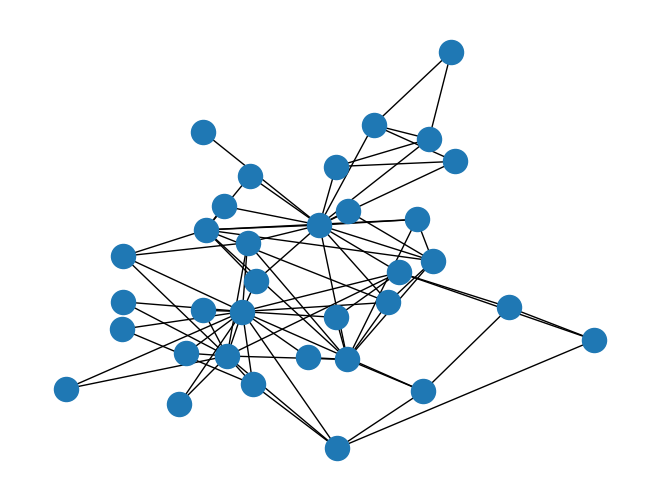

In [3]:
G = nx.karate_club_graph()
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos)

In [4]:
deg = G.degree()
print(deg)

[(0, 16), (1, 9), (2, 10), (3, 6), (4, 3), (5, 4), (6, 4), (7, 4), (8, 5), (9, 2), (10, 3), (11, 1), (12, 2), (13, 5), (14, 2), (15, 2), (16, 2), (17, 2), (18, 2), (19, 3), (20, 2), (21, 2), (22, 2), (23, 5), (24, 3), (25, 3), (26, 2), (27, 4), (28, 3), (29, 4), (30, 4), (31, 6), (32, 12), (33, 17)]


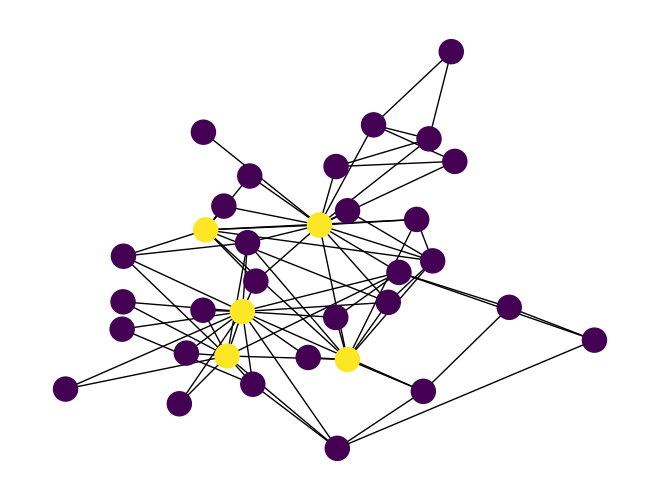

In [12]:
from sklearn.mixture import GaussianMixture
clf=GaussianMixture(n_components = 2)
deg = np.array(deg)
dclass = clf.fit_predict(deg[:, 1:])
dclass = np.array(dclass)
nx.draw(G, pos, node_color=dclass)

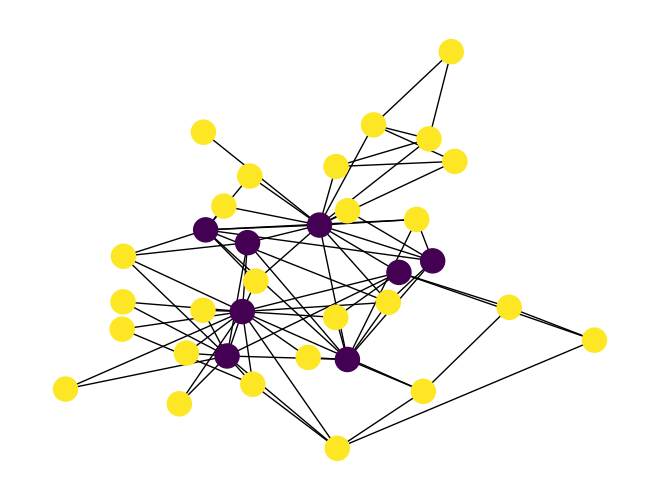

In [ ]:
G = nx.karate_club_graph()
pos = nx.kamada_kawai_layout(G)
deg = nx.betweenness_centrality(G)
clf = GaussianMixture(n_components=2)
deg = np.array([v for x, v in deg.items()])
degree = G.degree
nodes = list(G.nodes)
degree = np.array([degree[n] for n in nodes])
features = np.column_stack([deg, degree])
dclass = clf.fit_predict(features)

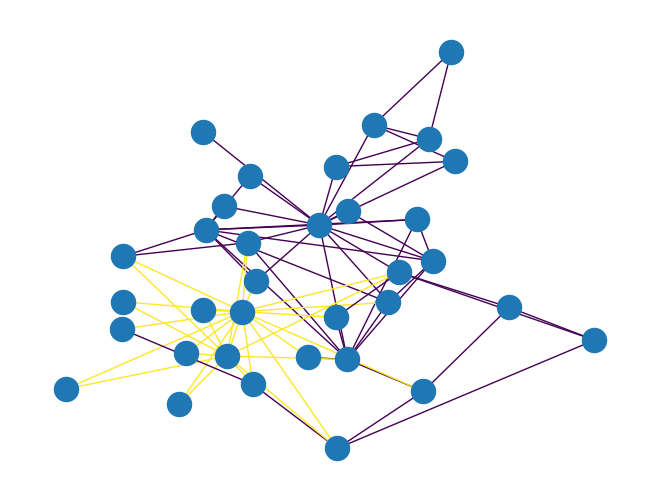

In [27]:
ed_e = []
for u, v in G.edges():
  ed_e.append([features[u, 0], features[u, 1], features[v, 0], features[v, 1]])
ed_e = np.array(ed_e)
dclass = clf.fit_predict(ed_e)
nx.draw(G, pos, edge_color=dclass)

[0.3888888888888889, 0.23809523809523808, 0.29411764705882354, 0.11764705882352941, 0.1111111111111111, 0.1111111111111111, 0.17647058823529413, 0.05, 0.11764705882352941, 0.0, 0.058823529411764705, 0.16666666666666666, 0.058823529411764705, 0.05555555555555555, 0.058823529411764705, 0.0, 0.26666666666666666, 0.36363636363636365, 0.3, 0.2727272727272727, 0.1, 0.09090909090909091, 0.1, 0.0, 0.3333333333333333, 0.2727272727272727, 0.15384615384615385, 0.0, 0.25, 0.0, 0.0, 0.047619047619047616, 0.42857142857142855, 0.14285714285714285, 0.375, 0.16666666666666666, 0.2, 0.3333333333333333, 0.16666666666666666, 0.2, 0.2, 0.2857142857142857, 0.21428571428571427, 0.1, 0.0, 0.0, 0.07692307692307693, 0.05555555555555555, 0.07692307692307693, 0.05555555555555555, 0.07692307692307693, 0.05555555555555555, 0.0, 0.07692307692307693, 0.05555555555555555, 0.07692307692307693, 0.05555555555555555, 0.0, 0.125, 0.2857142857142857, 0.13333333333333333, 0.15789473684210525, 0.2, 0.0, 0.125, 0.125, 0.2, 0.0

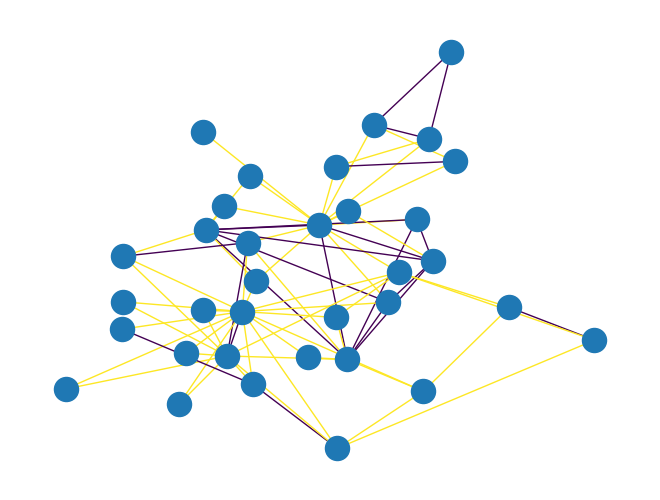

In [32]:
ed_e = []
for u, v in G.edges():
  ed_e.append(list(nx.jaccard_coefficient(G, [(u, v)]))[0][2])
print(list(ed_e))
ed_e = np.array(ed_e)[:, np.newaxis]
dclass = clf.fit_predict(ed_e)
nx.draw(G, pos, edge_color=dclass)

In [ ]:
### иднексджикардо
### иденкс каца